# Immediate-onset acoustic jumps: healthy Reynolds 100→150 vs first leak

## Executive summary

**Method:** For every run, sensor pair, and frequency, compare the **amplitude at the exact recorded event onset (`t0`)** with the median and MAD-based noise scale of the preceding **60 seconds**. Analyze both the healthy Reynolds **100→150** transition and the **first leak onset at Re=150**. When the onset leaves the existing **±2 robust-noise baseline band**, measure the **first observed return** within the following 60 seconds. Compare leak jumps with **16 sampled healthy Re=150 pseudo-onsets** per run and segment.

**Questions:** (1) Which frequencies and segments show a larger immediate response to leak onset than to a healthy Reynolds change? (2) How unusual is that response relative to sampled healthy fluctuations? (3) If there is an onset excursion, when does the signal first re-enter its previous baseline band?

**Result in this saved run:** f2500 and f3100 recur among the strongest immediate-onset responses, but `1213_1` is weak. **First return is not sustained recovery; these known-onset comparisons do not establish a field-ready detector or false-positive rate.**

**Notebook location:** `notebooks/`  
**Input:** `../data/all_segments.csv`  
**Outputs:** `../results/event_aligned_immediate_onset_jumps/`

## Exact event-boundary definition

We seek **large acoustic jumps in the first timestamp at the event itself**, not an arbitrary spike 5, 10, or 20 seconds later. Recovery is measured separately: find the **first subsequent observation** that returns to the original baseline band, within the existing 60-second post-event window. Record whether the very next sample returns as a distinct diagnostic. No delayed *jump* search is performed.

Both events are based on the experiment's recorded state boundaries, not inferred from the acoustic amplitudes:

- **Reynolds event:** healthy **100→150**, strictly before the first leak in each run.
- **Leak event:** first leak onset at Re=150, immediately following pre-first-leak healthy Re=150.

Work on signed `upstream_minus_downstream__f...` values, separately for each `run_id`, `segment_id` and frequency. Do not pool segments. Later `leak_active=False` periods are **never** treated as healthy.

## Event-onset measurements (no delayed jumps)

- **Pre-event baseline**: median of the retained 60-second pre-event window.
- **Pre-event noise**: `1.4826 × MAD` over that window.
- **Immediate signed jump**: **value at exactly t0 minus the pre-event baseline**.
- **Immediate normalized jump**: `abs(immediate signed jump)/pre-event noise`; undefined when noise is zero.
- **Boundary difference**: value at exactly t0 minus the immediately preceding measured value.
- **Onset excursion requirement**: recovery is applicable **only if the t0 measurement is outside the existing ±2 robust-sigma baseline band** (`onset Z > 2`). Otherwise, recovery is N/A and no green dot is displayed.
- **Next-sample return**: if an onset excursion exists, **the very next post-event measurement** falls within the original baseline band.
- **First observed recovery**: if an onset excursion exists, the first post-onset observation within that band, and elapsed time since t0, searched only within the existing post-event 60-second context.

The existing ±2 robust-sigma return band and 2.5-second maximum adjacent-sample gap for the *next-sample* check are retained as provisional criteria. The pre/post **60-second plotting context** and pre-event noise calculation do not expand the jump search. The recovery search uses the already configured `POST_WINDOW_S=60` as its observation horizon; this is not a new rapid-recovery threshold. If the first sample exactly at t0 is missing for a segment, the jump is **unavailable**, not shifted to a later sample.

The notebook also computes the **same immediate-onset measurement** at event-free healthy Re=150 pseudo-onsets for a descriptive background-jump comparison; it is not a calibrated false-positive rate. No threshold for the word "high" is invented: the tables rank by normalized immediate-jump magnitude and report next-sample return explicitly.


In [11]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# The notebook lives under notebooks/; also support launching with the repository as CWD.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data' / 'all_segments.csv'
OUT = ROOT / 'results' / 'event_aligned_immediate_onset_jumps'
PLOTS = OUT / 'event_plots'
SEGMENTS = ('UUS-US', 'US-DS', 'DS-DDS')

# Same experiment condition as established: first leak at Re=150;
# healthy flow transition of interest: Re=100 -> Re=150.
CHANGE_FROM = 100.0
CHANGE_TO = 150.0
LEAK_REYNOLDS = 150.0

# PRE_WINDOW_S and POST_WINDOW_S provide baseline/context ONLY, never peak search.
PRE_WINDOW_S = 60.0
POST_WINDOW_S = 60.0
# The ONLY eligible jump is the first sample exactly at event time t0.
LATE_WINDOW_S = 30.0
RETURN_BAND_SIGMA = 2.0
# Existing maximum gap for deciding whether the first next sample is adjacent.
MAX_ADJACENT_GAP_S = 2.5
MIN_PRE_SAMPLES = 30
MIN_PEAK_SAMPLES = 1
SHAM_STRIDE_S = 30.0

# Plot selection ONLY (all 26 frequencies are always analyzed).
PLOT_FREQUENCIES = ('f2500', 'f315','f250', 'f400','f500' ,'f630', 'f800','f1000','f160')

assert 0 < LATE_WINDOW_S <= POST_WINDOW_S
assert PRE_WINDOW_S > 0 and POST_WINDOW_S > 0
assert SHAM_STRIDE_S > 0
if not DATA.is_file():
    raise FileNotFoundError(f'Expected source data at {DATA.resolve()}')
OUT.mkdir(parents=True, exist_ok=True)
PLOTS.mkdir(parents=True, exist_ok=True)
print('Data:', DATA.resolve())
print('Output:', OUT.resolve())

Data: /home/ubuntu/notebooks/Leak_Detection_v1/temp/Leak_Detection/data/all_segments.csv
Output: /home/ubuntu/notebooks/Leak_Detection_v1/temp/Leak_Detection/results/event_aligned_immediate_onset_jumps


## 1. Read original timestamp-level segment data and identify event times

`Date-Time` means **elapsed seconds** in `all_segments.csv`. Determine the first-leak cutoff **per run from the full timeline**, before restricting any signal windows. A segment missing some synchronized timestamps must **not** shift the global event time for the other segments. Test consistency of Reynolds and leak flags across available segment rows at each timestamp.

In [2]:
df = pd.read_csv(DATA, low_memory=False)
required = ['run_id', 'segment_id', 'Date-Time', 'Reynolds_level',
            'leak_active', 'contains_leak_site']
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f'Missing required columns: {missing}')

frequency_columns = sorted(
    [c for c in df.columns if re.fullmatch(r'upstream_minus_downstream__f\d+(?:\.\d+)?', c)],
    key=lambda c: float(c.split('__f', 1)[1])
)
if not frequency_columns:
    raise ValueError('No upstream_minus_downstream__f... frequency columns found')
FREQUENCIES = [c.split('__', 1)[1] for c in frequency_columns]

def to_bool(col):
    result = col.astype(str).str.strip().str.lower().map(
        {'true': True, 'false': False, '1': True, '0': False}
    )
    if result.isna().any():
        raise ValueError(f'Invalid Boolean values in {col.name}')
    return result.astype(bool)

df['leak_active'] = to_bool(df['leak_active'])
df['contains_leak_site'] = to_bool(df['contains_leak_site'])
df['Date-Time'] = pd.to_numeric(df['Date-Time'], errors='raise')
df['Reynolds_level'] = pd.to_numeric(df['Reynolds_level'], errors='raise')
for c in frequency_columns:
    df[c] = pd.to_numeric(df[c], errors='raise')
if df[['Date-Time', 'Reynolds_level']].isna().any().any():
    raise ValueError('Date-Time and Reynolds_level must not have missing values')
if not df['segment_id'].isin(SEGMENTS).all():
    raise ValueError('Unexpected segment_id')
if not (df['contains_leak_site'] == df['segment_id'].eq('US-DS')).all():
    raise ValueError('contains_leak_site contradicts known US-DS leak location')
if df.duplicated(['run_id', 'segment_id', 'Date-Time']).any():
    raise ValueError('Duplicate run_id / segment_id / Date-Time')

# The physical event labels are common to the entire run, regardless of segment.
inconsistency = (df.groupby(['run_id', 'Date-Time'])
                 .agg(levels=('Reynolds_level', 'nunique'), leak_flags=('leak_active', 'nunique')))
if (inconsistency[['levels', 'leak_flags']] > 1).any().any():
    raise ValueError('Conflicting Reynolds/leak status across pairs at same run/time')

timeline = (df.groupby(['run_id', 'Date-Time'], as_index=False, sort=True)
            .agg(Reynolds_level=('Reynolds_level', 'first'),
                 leak_active=('leak_active', 'first'))
            .sort_values(['run_id', 'Date-Time']).reset_index(drop=True))
first_leak_by_run = (timeline.loc[timeline.leak_active]
                     .groupby('run_id')['Date-Time'].min())
missing_leaks = sorted(set(df.run_id.unique()) - set(first_leak_by_run.index))
if missing_leaks:
    raise ValueError(f'No first leak observed in run(s) {missing_leaks}')

df['pre_first_leak'] = df['Date-Time'] < df['run_id'].map(first_leak_by_run)
df = df.sort_values(['run_id', 'segment_id', 'Date-Time']).reset_index(drop=True)

print(f'Loaded {len(df):,} rows, {df.run_id.nunique()} experiments, '
      f'{df.segment_id.nunique()} probe pairs, {len(FREQUENCIES)} frequencies')
print('First leak (global per run, from unfiltered data):')
display(first_leak_by_run.rename('first_leak_s').reset_index())

Loaded 161,114 rows, 5 experiments, 3 probe pairs, 26 frequencies
First leak (global per run, from unfiltered data):


,run_id,first_leak_s
0,1211_1,3000.0
1,1212_1,3000.0
2,1212_2,3000.0
3,1213_1,3300.0
4,1213_2,3000.0


### Result interpretation — data coverage and event times

- The saved execution loaded **161,114 rows**, covering **5 experiments**, **3 adjacent probe pairs**, and **26 frequencies**. Every acoustic value is a **signed upstream-minus-downstream difference**, evaluated per segment rather than pooled.
- First leak begins at **t=3,000 s** for `1211_1`, `1212_1`, `1212_2`, and `1213_2`, versus **t=3,300 s** for `1213_1`.
- **Conclusion:** Each experiment has a run-level leak reference time. All segments must use that same timestamp even when their acoustic responses differ.


## 2. Identify the 100→150 healthy transition and first leak, per run

The Reynolds event begins when `Reynolds_level` first changes **100→150** while still strictly before the first leak. Keep every matching pre-leak transition in the results. The first-leak event is the **first `leak_active=True` timestamp**, not a later leak or later inactive period. Both events are anchored to the **run-level** timeline, not inferred from amplitude spikes.

In [3]:
event_rows = []
for run, g in timeline.groupby('run_id', sort=True):
    g = g.sort_values('Date-Time').reset_index(drop=True)
    leak_t = float(first_leak_by_run.loc[run])
    pre = g.loc[g['Date-Time'] < leak_t].copy()
    prior_level = pre['Reynolds_level'].shift()
    transitions = pre.loc[(prior_level == CHANGE_FROM) &
                          (pre['Reynolds_level'] == CHANGE_TO)]
    for j, (_, row) in enumerate(transitions.iterrows(), 1):
        event_rows.append({'run_id': run, 'event_type': 're_100_to_150',
                           'event_number': j, 'event_s': float(row['Date-Time'])})
    leak_row = g.loc[g['Date-Time'].eq(leak_t)].iloc[0]
    if float(leak_row['Reynolds_level']) != LEAK_REYNOLDS:
        raise ValueError(f'First leak at Re={leak_row["Reynolds_level"]} in run {run}, expected Re=150')
    event_rows.append({'run_id': run, 'event_type': 'first_leak',
                       'event_number': 1, 'event_s': leak_t})

events = pd.DataFrame(event_rows, columns=['run_id', 'event_type', 'event_number', 'event_s'])
events['event_id'] = (events['run_id'].astype(str) + '|' +
                      events['event_type'] + '|' +
                      events['event_number'].astype(str))
assert not events.duplicated(['run_id', 'event_id']).any()
if not events['event_type'].eq('re_100_to_150').any():
    raise ValueError('No healthy 100→150 transitions found before first leaks')
events.to_csv(OUT / 'event_inventory.csv', index=False)
display(events)

,run_id,event_type,event_number,event_s,event_id
0,1211_1,re_100_to_150,1,2400.0,1211_1|re_100_to_150|1
1,1211_1,first_leak,1,3000.0,1211_1|first_leak|1
2,1212_1,re_100_to_150,1,2400.0,1212_1|re_100_to_150|1
3,1212_1,first_leak,1,3000.0,1212_1|first_leak|1
4,1212_2,re_100_to_150,1,2400.0,1212_2|re_100_to_150|1
5,1212_2,first_leak,1,3000.0,1212_2|first_leak|1
6,1213_1,re_100_to_150,1,2700.0,1213_1|re_100_to_150|1
7,1213_1,first_leak,1,3300.0,1213_1|first_leak|1
8,1213_2,re_100_to_150,1,2400.0,1213_2|re_100_to_150|1
9,1213_2,first_leak,1,3000.0,1213_2|first_leak|1


### Result interpretation — two physical events per experiment

- The event table contains **10 recorded event boundaries**: one healthy Reynolds **100→150** transition and one first-leak onset for each of the **5 runs**.
- Reynolds transitions occur at **t=2,400 s** in four runs and **t=2,700 s** in `1213_1`; the corresponding first leaks occur **600 seconds later**.
- **Conclusion:** The comparison distinguishes a normal flow transition from first leak onset, using recorded events rather than searching for whichever acoustic spike is largest.


## 3. Exact event-onset jump and first observed recovery

Only the sample at the recorded event time `t0` can be a jump. **A recovery is defined only when that sample is outside the existing ±2 robust-sigma baseline band.** When `onset Z <= 2`, recovery is N/A. Otherwise search subsequent observed samples in the **existing 60-second post-event window** for the first return to the pre-event baseline band. Report the original **very-next-sample** return result separately. No delayed peaks qualify; a recovery at a later time is not a later peak.

For healthy Reynolds 100→150, both sides must be healthy and before first leak. For first leak, only the first leak period is eligible. Missing synchronization at `t0` means **unavailable for that segment**, with the other segments retained. Raw amplitude series are neither smoothed nor resampled.


In [4]:
def robust_sigma(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return np.nan
    mid = np.median(x)
    return float(1.4826 * np.median(np.abs(x - mid)))


def first_leak_block_end(run_timeline, onset):
    """Return first timestamp of an inactive observation after first leak starts.
    If the observed recording ends while the first leak remains active, return +inf.
    """
    g = run_timeline.loc[run_timeline['Date-Time'] >= onset].sort_values('Date-Time')
    stop = g.loc[~g.leak_active, 'Date-Time']
    return float(stop.min()) if len(stop) else float('inf')

leak_end_by_run = {
    run: first_leak_block_end(g, float(first_leak_by_run.loc[run]))
    for run, g in timeline.groupby('run_id', sort=False)
}


def event_windows(segment_data, run, onset, event_type):
    """Return raw pre/post rows matching the established physical state boundaries."""
    d = segment_data
    pre = d.loc[(d['Date-Time'] >= onset - PRE_WINDOW_S) &
                (d['Date-Time'] < onset)]
    post = d.loc[(d['Date-Time'] >= onset) &
                 (d['Date-Time'] <= onset + POST_WINDOW_S)]
    if event_type == 're_100_to_150':
        pre = pre.loc[(pre.Reynolds_level == CHANGE_FROM) &
                      (~pre.leak_active) & pre.pre_first_leak]
        post = post.loc[(post.Reynolds_level == CHANGE_TO) &
                        (~post.leak_active) & post.pre_first_leak]
    elif event_type == 'first_leak':
        pre = pre.loc[(pre.Reynolds_level == LEAK_REYNOLDS) &
                      (~pre.leak_active) & pre.pre_first_leak]
        post = post.loc[(post.Reynolds_level == LEAK_REYNOLDS) &
                        post.leak_active &
                        (post['Date-Time'] < leak_end_by_run[run])]
    elif event_type == 'healthy_sham':
        pre = pre.loc[(pre.Reynolds_level == LEAK_REYNOLDS) &
                      (~pre.leak_active) & pre.pre_first_leak]
        post = post.loc[(post.Reynolds_level == LEAK_REYNOLDS) &
                        (~post.leak_active) & post.pre_first_leak]
    else:
        raise ValueError(f'Unrecognized event type: {event_type}')
    return pre, post


def transient_metrics(pre, post, feature, onset):
    """Jump only at t0; recovery is the first observed return in the existing post window.

    No peak-search window: an amplitude extreme later than t0 is ignored.
    """
    b = pre[['Date-Time', feature]].dropna().sort_values('Date-Time')
    a = post[['Date-Time', feature]].dropna().sort_values('Date-Time')
    result = dict(n_pre=len(b), n_post=len(a),
                  baseline=np.nan, baseline_sigma=np.nan,
                  first_sample_jump=np.nan, peak_signed=np.nan, peak_abs=np.nan,
                  peak_z=np.nan, time_to_peak_s=np.nan,
                  recovery_time_s=np.nan, returned_to_baseline=False,
                  late_baseline_shift=np.nan, peak_s=np.nan, recovery_s=np.nan,
                  next_sample_s=np.nan, next_sample_deviation=np.nan,
                  next_sample_returned_to_baseline=False)
    if len(b) < MIN_PRE_SAMPLES:
        result['status'] = 'insufficient_pre_samples'
        return result

    B = float(b[feature].median())
    sigma = robust_sigma(b[feature])
    result.update(baseline=B, baseline_sigma=sigma)

    # Require event-aligned measurement AT t0, not first available at t0+N.
    onset_reading = a.loc[a['Date-Time'].eq(onset)]
    if onset_reading.empty:
        result['status'] = 'event_onset_sample_missing'
        return result
    if b.empty or not (0 < onset - float(b.iloc[-1]['Date-Time']) <= MAX_ADJACENT_GAP_S):
        result['status'] = 'no_adjacent_pre_event_sample'
        return result

    y0 = float(onset_reading.iloc[0][feature])
    signed = y0 - B
    result.update(status='ok', peak_signed=signed,
                  peak_abs=abs(signed),
                  peak_z=(abs(signed)/sigma if np.isfinite(sigma) and sigma>0 else np.nan),
                  time_to_peak_s=0.0, peak_s=float(onset),
                  first_sample_jump=(y0 - float(b.iloc[-1][feature])))

    # Existing next-sample check, retained as a SEPARATE diagnostic.
    after_onset = a.loc[a['Date-Time'] > onset]
    immediately_after = after_onset.head(1)
    if immediately_after.empty:
        result['status'] = 'no_next_sample_to_check_return'
        return result
    next_t = float(immediately_after.iloc[0]['Date-Time'])
    next_y = float(immediately_after.iloc[0][feature])
    result['next_sample_s'] = next_t
    result['next_sample_deviation'] = next_y - B
    if not (0 < next_t - onset <= MAX_ADJACENT_GAP_S):
        result['status'] = 'next_sample_not_adjacent'
    if np.isfinite(sigma) and sigma > 0:
        band = RETURN_BAND_SIGMA * sigma
        # Recovery is meaningful only if the t0 measurement LEFT the baseline band.
        # Reuse the existing return band; no additional threshold or peak search.
        if abs(signed) <= band:
            result['status'] = 'no_onset_excursion'
            return result
        result['next_sample_returned_to_baseline'] = bool(
            (next_t - onset <= MAX_ADJACENT_GAP_S) and abs(next_y - B) <= band
        )
        # First OBSERVED post-onset sample in the baseline band. No new cutoff:
        # after_onset already belongs to the existing POST_WINDOW_S window.
        recovered = after_onset.loc[(after_onset[feature] - B).abs() <= band]
        if not recovered.empty:
            first_t = float(recovered.iloc[0]['Date-Time'])
            result['recovery_time_s'] = first_t - onset
            result['recovery_s'] = first_t
            result['returned_to_baseline'] = True
    return result


In [5]:
segment_groups = {
    (run, seg): g.sort_values('Date-Time').reset_index(drop=True)
    for (run, seg), g in df.groupby(['run_id', 'segment_id'], sort=True)
}
metric_rows = []
for evt in events.itertuples(index=False):
    for seg in SEGMENTS:
        key = (evt.run_id, seg)
        if key not in segment_groups:
            continue
        pre, post = event_windows(segment_groups[key], evt.run_id,
                                  evt.event_s, evt.event_type)
        for feature in frequency_columns:
            metric_rows.append(dict(run_id=evt.run_id, segment_id=seg,
                                    contains_leak_site=(seg == 'US-DS'),
                                    event_id=evt.event_id, event_type=evt.event_type,
                                    event_s=evt.event_s, frequency=feature.split('__',1)[1],
                                    **transient_metrics(pre, post, feature, evt.event_s)))

event_metrics = pd.DataFrame(metric_rows)
event_metrics.to_csv(OUT / 'event_aligned_transient_metrics.csv', index=False)
assert not event_metrics.duplicated(['event_id', 'segment_id', 'frequency']).any()
print('Real-event metrics:', len(event_metrics))
display(event_metrics.groupby(['run_id', 'segment_id', 'event_type', 'status'])
        .size().rename('frequencies').reset_index())

Real-event metrics: 780


,run_id,segment_id,event_type,status,frequencies
0,1211_1,DS-DDS,first_leak,no_onset_excursion,24
1,1211_1,DS-DDS,first_leak,ok,2
2,1211_1,DS-DDS,re_100_to_150,no_onset_excursion,25
3,1211_1,DS-DDS,re_100_to_150,ok,1
4,1211_1,US-DS,first_leak,no_onset_excursion,22
5,1211_1,US-DS,first_leak,ok,4
6,1211_1,US-DS,re_100_to_150,no_onset_excursion,24
7,1211_1,US-DS,re_100_to_150,ok,2
8,1211_1,UUS-US,first_leak,no_onset_excursion,15
9,1211_1,UUS-US,first_leak,ok,11


### Result interpretation — exact-onset excursion coverage

- The notebook generates **780 event-level frequency measurements** (`10 events × 3 segments × 26 frequencies`). The displayed `status` counts reflect whether the *exact onset* leaves the original baseline band; they are **not detector true-positive or false-positive counts**.
- For first-leak events, the saved status table shows **31 qualifying onset excursions across 78 segment-frequency cases** in `1212_1`, compared with only **2 of 78** in `1213_1`. This is a major difference in sensitivity of the immediate-onset signature across experiments.
- **Conclusion:** Strong leak-onset excursions are not consistent across runs. For `onset Z ≤ 2`, recovery is correctly **N/A**, not zero seconds.


## 4. Event-free healthy comparison: the *same immediate jump* test

Candidate pseudo-onsets lie inside healthy Re=150 **before first leak**. At each pseudo-onset, measure **only its t0 sample**, check next-sample return separately, and record recovery only when the onset sample first leaves the original baseline band. The pre/post 60-second windows ensure healthy, unchanged operating conditions and provide baseline/context; they are **not a peak-search window**. The returned fraction is descriptive, not a calibrated false-positive rate.


In [6]:
sham_rows = []
sham_inventory = []
for (run, seg), d in segment_groups.items():
    healthy_150 = d.loc[d.pre_first_leak & (~d.leak_active) &
                        d.Reynolds_level.eq(LEAK_REYNOLDS)]
    # Candidate times are the original observed timestamps, not a resampled grid.
    times = healthy_150['Date-Time'].to_numpy(dtype=float)
    last_selected = -np.inf
    sham_no = 0
    for onset in times:
        if onset - last_selected < SHAM_STRIDE_S:
            continue
        pre, post = event_windows(d, run, float(onset), 'healthy_sham')
        # Require the complete configured time span to remain inside ONE stable-Re period.
        # These checks select valid event-free comparisons; they are not applied to real events.
        if (pre.empty or post.empty or
            pre['Date-Time'].min() > onset-PRE_WINDOW_S+MAX_ADJACENT_GAP_S or
            post['Date-Time'].max() < onset+POST_WINDOW_S-MAX_ADJACENT_GAP_S or
            len(pre) < MIN_PRE_SAMPLES or len(post) < MIN_PEAK_SAMPLES):
            continue
        # There must be NO event/state boundary within the full nominal window.
        state_window = d.loc[(d['Date-Time'] >= onset-PRE_WINDOW_S) &
                             (d['Date-Time'] <= onset+POST_WINDOW_S)]
        if (state_window['Reynolds_level'].nunique() != 1 or
            state_window['leak_active'].any() or
            (~state_window.pre_first_leak).any()):
            continue
        sham_no += 1
        last_selected = float(onset)
        sham_inventory.append({'run_id':run, 'segment_id':seg,
                               'sham_number':sham_no, 'event_s':float(onset)})
        for feature in frequency_columns:
            sham_rows.append(dict(run_id=run, segment_id=seg,
                                  frequency=feature.split('__',1)[1],
                                  sham_number=sham_no, event_s=float(onset),
                                  **transient_metrics(pre, post, feature, float(onset))))

sham_metrics = pd.DataFrame(sham_rows)
if sham_metrics.empty:
    print('WARNING: no complete event-free healthy Re=150 windows were available.')
    sham_summary = pd.DataFrame(columns=['run_id','segment_id','frequency',
                                         'n_healthy_shams','healthy_peak_z_p95',
                                         'healthy_peak_z_max'])
else:
    sham_summary = (sham_metrics.groupby(['run_id','segment_id','frequency'],sort=True)
        .agg(n_healthy_shams=('peak_z','count'),
             healthy_peak_z_p95=('peak_z',lambda v:v.quantile(0.95)),
             healthy_peak_z_max=('peak_z','max'))
        .reset_index())

pd.DataFrame(sham_inventory, columns=['run_id','segment_id','sham_number','event_s']).to_csv(
    OUT / 'healthy_sham_event_inventory.csv', index=False)
sham_metrics.to_csv(OUT / 'healthy_sham_transient_metrics.csv', index=False)
sham_summary.to_csv(OUT / 'healthy_sham_peak_summary.csv', index=False)
print('Healthy pseudo-events:',len(sham_inventory))
display(sham_summary.head(12))

Healthy pseudo-events: 240


,run_id,segment_id,frequency,n_healthy_shams,healthy_peak_z_p95,healthy_peak_z_max
0,1211_1,DS-DDS,f100,16,1.819388,2.306651
1,1211_1,DS-DDS,f1000,16,2.167992,2.361546
2,1211_1,DS-DDS,f10000,16,2.193075,2.659443
3,1211_1,DS-DDS,f125,16,1.936784,3.022974
4,1211_1,DS-DDS,f1250,16,1.854872,1.874191
5,1211_1,DS-DDS,f160,16,1.540345,1.924265
6,1211_1,DS-DDS,f1600,16,2.117294,2.282984
7,1211_1,DS-DDS,f200,16,1.467582,1.718044
8,1211_1,DS-DDS,f2000,16,2.036608,2.485698
9,1211_1,DS-DDS,f25,16,1.889157,1.948385


### Result interpretation — healthy pseudo-onset reference

- The saved run tests **240 healthy pseudo-event timestamps** in total (**16 per run and segment**), within healthy **Re=150** operation before the first leak. Each frequency is measured at those same candidate times.
- `healthy_peak_z_p95` summarizes the upper tail of these sampled immediate jumps; `healthy_peak_exceedance_fraction` later compares them with the actual leak-onset Z for the **same run, segment, and frequency**.
- **Conclusion:** A small exceedance fraction is encouraging *within these sampled healthy windows*. With only **16 comparison timestamps per run/segment**, even `0.0` does **not** establish a low continuous-operation false-positive rate.


## 5. Same-run/segment/frequency Reynolds versus leak onset comparison

Each `peak_*` column in saved tables is now **strictly the jump at the event-onset sample, t0** (kept for compatibility with the previous notebook's column names). `time_to_peak_s` is always 0 when available. `returned_to_baseline=True` means **t0 first leaves the original ±2 robust-sigma band and then some observed sample after t0 returns inside that band** within the existing 60-second window; `recovery_time_s` gives the time of its first observed return. `next_sample_returned_to_baseline` records the original adjacent-next-sample check separately. The original tables retain missing cases as `NaN`, not zero. The healthy comparison uses exactly the same t0-only definition.


In [7]:
# One row per run, segment, frequency for the leak event.
leak_metrics = event_metrics.loc[event_metrics.event_type.eq('first_leak')].copy()
leak_metrics = leak_metrics.rename(columns={
    'peak_signed':'leak_peak_signed', 'peak_abs':'leak_peak_abs',
    'peak_z':'leak_peak_z', 'time_to_peak_s':'leak_time_to_peak_s',
    'recovery_time_s':'leak_recovery_time_s',
    'returned_to_baseline':'leak_returned_to_baseline',
    'next_sample_returned_to_baseline':'leak_next_sample_returned_to_baseline',
    'late_baseline_shift':'leak_late_baseline_shift', 'status':'leak_status',
    'first_sample_jump':'leak_first_sample_jump'
})
leak_cols = ['run_id','segment_id','frequency','contains_leak_site',
             'leak_status','leak_peak_signed','leak_peak_abs','leak_peak_z',
             'leak_time_to_peak_s','leak_recovery_time_s',
             'leak_returned_to_baseline','leak_next_sample_returned_to_baseline',
             'leak_late_baseline_shift',
             'leak_first_sample_jump']

re_metrics = (event_metrics.loc[event_metrics.event_type.eq('re_100_to_150')]
              .sort_values(['run_id','segment_id','frequency','event_s'])
              .drop_duplicates(['run_id','segment_id','frequency'], keep='last'))
re_metrics = re_metrics.rename(columns={
    'peak_signed':'re_peak_signed', 'peak_abs':'re_peak_abs',
    'peak_z':'re_peak_z', 'time_to_peak_s':'re_time_to_peak_s',
    'recovery_time_s':'re_recovery_time_s',
    'returned_to_baseline':'re_returned_to_baseline',
    'next_sample_returned_to_baseline':'re_next_sample_returned_to_baseline',
    'late_baseline_shift':'re_late_baseline_shift', 'status':'re_status'
})
re_cols = ['run_id','segment_id','frequency','re_status',
           're_peak_signed','re_peak_abs','re_peak_z',
           're_time_to_peak_s','re_recovery_time_s','re_returned_to_baseline',
           're_next_sample_returned_to_baseline','re_late_baseline_shift']
comparison = (leak_metrics[leak_cols]
              .merge(re_metrics[re_cols], on=['run_id','segment_id','frequency'],
                     how='outer', validate='one_to_one')
              .merge(sham_summary, on=['run_id','segment_id','frequency'],
                     how='left', validate='one_to_one'))

# Exact control exceedance for the same run/segment/frequency; no pooling of locations.
if not sham_metrics.empty:
    leak_z = comparison.set_index(['run_id','segment_id','frequency'])['leak_peak_z']
    def exceedance(group):
        key = group.name
        observed = leak_z.get(key, np.nan)
        vals = group['peak_z'].dropna()
        if not np.isfinite(observed) or not len(vals):
            return np.nan
        return float((vals >= observed).mean())
    exceedance_df = (sham_metrics.groupby(['run_id','segment_id','frequency'])
                     .apply(exceedance, include_groups=False)
                     .rename('healthy_peak_exceedance_fraction').reset_index())
    comparison = comparison.merge(exceedance_df,
                                  on=['run_id','segment_id','frequency'],
                                  how='left',validate='one_to_one')
else:
    comparison['healthy_peak_exceedance_fraction'] = np.nan

comparison.to_csv(OUT / 'transient_reynolds_vs_first_leak_comparison.csv', index=False)
assert not comparison.duplicated(['run_id','segment_id','frequency']).any()
print('Comparison rows:',len(comparison))
print('All columns:',list(comparison.columns))

Comparison rows: 390
All columns: ['run_id', 'segment_id', 'frequency', 'contains_leak_site', 'leak_status', 'leak_peak_signed', 'leak_peak_abs', 'leak_peak_z', 'leak_time_to_peak_s', 'leak_recovery_time_s', 'leak_returned_to_baseline', 'leak_next_sample_returned_to_baseline', 'leak_late_baseline_shift', 'leak_first_sample_jump', 're_status', 're_peak_signed', 're_peak_abs', 're_peak_z', 're_time_to_peak_s', 're_recovery_time_s', 're_returned_to_baseline', 're_next_sample_returned_to_baseline', 're_late_baseline_shift', 'n_healthy_shams', 'healthy_peak_z_p95', 'healthy_peak_z_max', 'healthy_peak_exceedance_fraction']


### Result interpretation — one-to-one leak, Reynolds, and healthy comparison

- **390 comparison rows** represent **5 runs × 3 segments × 26 frequencies**, retaining each segment independently.
- Read **`leak_peak_z` (prefer high)** alongside **`re_peak_z` (prefer low)** and **`healthy_peak_z_p95` / `healthy_peak_exceedance_fraction` (prefer low relative to leak response)**. The Z-scores use *different pre-event noise baselines* because the Reynolds and leak reference periods have different operating conditions.
- **Conclusion:** This table supports descriptive *event discrimination*, not a causal effect estimate or an operational detection-performance estimate. `leak_late_baseline_shift` is not computed by the current metric function (remains `NaN`); an apparent sustained shift in the plots is therefore **not quantified** here.


## 6. Per-experiment ranking: **immediate event-onset jumps only**

Display the five largest normalized **t0** jumps in each run and segment. The `leak_returned_to_baseline` flag records whether an observed return occurred **after an actual onset excursion outside the original baseline band**; `leak_next_sample_returned_to_baseline` preserves the stricter very-next-sample check. The actual first return time is in `leak_recovery_time_s`. A later spike cannot enter this ranking, regardless of its size. No minimum jump threshold has been introduced.


In [8]:
ESSENTIAL = [
    'run_id','segment_id','frequency','contains_leak_site',
    'leak_peak_signed','leak_peak_z','leak_time_to_peak_s',
    'leak_recovery_time_s','leak_returned_to_baseline',
    'leak_next_sample_returned_to_baseline','leak_late_baseline_shift',
    're_peak_signed','re_peak_z','re_time_to_peak_s',
    're_recovery_time_s','re_next_sample_returned_to_baseline',
    'n_healthy_shams','healthy_peak_z_p95',
    'healthy_peak_exceedance_fraction'
]
comparison_essential = comparison[ESSENTIAL].copy()
for run, g in comparison_essential.groupby('run_id', sort=True):
    for seg in SEGMENTS:
        ranked = g.loc[g.segment_id.eq(seg)].sort_values('leak_peak_z', ascending=False)
        if ranked.empty:
            continue
        print(f'\n{run} / {seg}: largest t0 first-leak jumps (first recovery time and next-sample return shown)')
        display(ranked.head(5))

comparison_essential.to_csv(OUT / 'transient_comparison_essential.csv', index=False)


1211_1 / UUS-US: largest t0 first-leak jumps (first recovery time and next-sample return shown)


,run_id,segment_id,frequency,contains_leak_site,leak_peak_signed,leak_peak_z,leak_time_to_peak_s,leak_recovery_time_s,leak_returned_to_baseline,leak_next_sample_returned_to_baseline,leak_late_baseline_shift,re_peak_signed,re_peak_z,re_time_to_peak_s,re_recovery_time_s,re_next_sample_returned_to_baseline,n_healthy_shams,healthy_peak_z_p95,healthy_peak_exceedance_fraction
71,1211_1,UUS-US,f5000,False,13.600465,94.349093,0.0,5.0,True,False,NaN,1.428943,1.793030,0.0,NaN,False,16,1.638520,0.0
64,1211_1,UUS-US,f3100,False,12.833568,58.845778,0.0,6.0,True,False,NaN,-0.176248,0.216334,0.0,NaN,False,16,2.519105,0.0
68,1211_1,UUS-US,f4000,False,18.233889,39.847634,0.0,3.0,True,False,NaN,0.325943,0.361651,0.0,NaN,False,16,2.303524,0.0
74,1211_1,UUS-US,f6300,False,9.812073,14.448666,0.0,3.0,True,False,NaN,1.630432,1.883345,0.0,NaN,False,16,2.768768,0.0
60,1211_1,UUS-US,f2000,False,4.669618,12.308776,0.0,2.0,True,False,NaN,0.457410,0.635256,0.0,NaN,False,16,2.146036,0.0



1211_1 / US-DS: largest t0 first-leak jumps (first recovery time and next-sample return shown)


,run_id,segment_id,frequency,contains_leak_site,leak_peak_signed,leak_peak_z,leak_time_to_peak_s,leak_recovery_time_s,leak_returned_to_baseline,leak_next_sample_returned_to_baseline,leak_late_baseline_shift,re_peak_signed,re_peak_z,re_time_to_peak_s,re_recovery_time_s,re_next_sample_returned_to_baseline,n_healthy_shams,healthy_peak_z_p95,healthy_peak_exceedance_fraction
37,1211_1,US-DS,f2500,True,-3.617734,4.618585,0.0,1.0,True,True,NaN,-0.666801,0.638005,0.0,NaN,False,16,1.543312,0.000
34,1211_1,US-DS,f2000,True,-1.377478,2.940083,0.0,1.0,True,True,NaN,-0.821013,1.384256,0.0,NaN,False,16,1.898061,0.000
38,1211_1,US-DS,f3100,True,-1.813850,2.677985,0.0,1.0,True,True,NaN,-0.314949,0.285346,0.0,NaN,False,16,1.537565,0.000
51,1211_1,US-DS,f8000,True,-1.800525,2.198170,0.0,2.0,True,False,NaN,-0.874960,1.027265,0.0,NaN,False,16,2.401879,0.125
27,1211_1,US-DS,f1000,True,1.500684,1.944313,0.0,NaN,False,False,NaN,1.037684,1.355040,0.0,NaN,False,16,2.210103,0.125



1211_1 / DS-DDS: largest t0 first-leak jumps (first recovery time and next-sample return shown)


,run_id,segment_id,frequency,contains_leak_site,leak_peak_signed,leak_peak_z,leak_time_to_peak_s,leak_recovery_time_s,leak_returned_to_baseline,leak_next_sample_returned_to_baseline,leak_late_baseline_shift,re_peak_signed,re_peak_z,re_time_to_peak_s,re_recovery_time_s,re_next_sample_returned_to_baseline,n_healthy_shams,healthy_peak_z_p95,healthy_peak_exceedance_fraction
11,1211_1,DS-DDS,f2500,False,5.784199,5.402473,0.0,10.0,True,False,NaN,0.329772,0.324821,0.0,NaN,False,16,1.384779,0.0000
16,1211_1,DS-DDS,f4000,False,-3.088648,2.859788,0.0,2.0,True,False,NaN,0.910531,0.868865,0.0,NaN,False,16,2.240268,0.0625
12,1211_1,DS-DDS,f3100,False,1.557881,1.918914,0.0,NaN,False,False,NaN,0.756346,0.813679,0.0,NaN,False,16,1.378231,0.0000
20,1211_1,DS-DDS,f63,False,-2.016573,1.883438,0.0,NaN,False,False,NaN,2.772621,1.574465,0.0,NaN,False,16,2.301451,0.1875
25,1211_1,DS-DDS,f8000,False,1.583664,1.620792,0.0,NaN,False,False,NaN,-0.284420,0.359367,0.0,NaN,False,16,1.748636,0.1250


... (20 outputs left out)


1213_2 / US-DS: largest t0 first-leak jumps (first recovery time and next-sample return shown)


,run_id,segment_id,frequency,contains_leak_site,leak_peak_signed,leak_peak_z,leak_time_to_peak_s,leak_recovery_time_s,leak_returned_to_baseline,leak_next_sample_returned_to_baseline,leak_late_baseline_shift,re_peak_signed,re_peak_z,re_time_to_peak_s,re_recovery_time_s,re_next_sample_returned_to_baseline,n_healthy_shams,healthy_peak_z_p95,healthy_peak_exceedance_fraction
350,1213_2,US-DS,f3100,True,3.629794,6.427321,0.0,1.0,True,True,NaN,0.154942,0.527259,0.0,NaN,False,16,1.889263,0.000
349,1213_2,US-DS,f2500,True,3.361001,5.438297,0.0,1.0,True,True,NaN,-0.042729,0.118411,0.0,NaN,False,16,1.747908,0.000
354,1213_2,US-DS,f4000,True,2.396634,4.675263,0.0,1.0,True,True,NaN,-0.419245,0.290624,0.0,NaN,False,16,1.652765,0.000
357,1213_2,US-DS,f5000,True,1.154482,3.173758,0.0,1.0,True,True,NaN,0.220194,0.477131,0.0,NaN,False,16,1.490247,0.000
355,1213_2,US-DS,f50,True,5.695496,1.707102,0.0,NaN,False,False,NaN,3.261443,1.569732,0.0,NaN,False,16,2.229760,0.125



1213_2 / DS-DDS: largest t0 first-leak jumps (first recovery time and next-sample return shown)


,run_id,segment_id,frequency,contains_leak_site,leak_peak_signed,leak_peak_z,leak_time_to_peak_s,leak_recovery_time_s,leak_returned_to_baseline,leak_next_sample_returned_to_baseline,leak_late_baseline_shift,re_peak_signed,re_peak_z,re_time_to_peak_s,re_recovery_time_s,re_next_sample_returned_to_baseline,n_healthy_shams,healthy_peak_z_p95,healthy_peak_exceedance_fraction
321,1213_2,DS-DDS,f25,False,-8.582465,2.048015,0.0,1.0,True,True,NaN,-5.239116,1.377174,0.0,NaN,False,16,1.813576,0.0000
328,1213_2,DS-DDS,f4000,False,-1.673380,1.832582,0.0,NaN,False,False,NaN,1.119721,1.034222,0.0,NaN,False,16,1.856135,0.0625
334,1213_2,DS-DDS,f6300,False,0.775468,1.736527,0.0,NaN,False,False,NaN,-1.022325,1.058638,0.0,NaN,False,16,1.837853,0.0625
335,1213_2,DS-DDS,f80,False,4.267013,1.498817,0.0,NaN,False,False,NaN,1.195603,0.322582,0.0,NaN,False,16,2.183273,0.1250
323,1213_2,DS-DDS,f2500,False,0.758842,1.302310,0.0,NaN,False,False,NaN,0.662171,0.751511,0.0,NaN,False,16,4.366848,0.2500


### Result interpretation — top-five ranking across all three segments

- Each of the **15 run/segment combinations** displays its **five highest `leak_peak_z` values**: **75 displayed rows** total. The ranking criterion is **only the normalized immediate leak-onset jump**, not a composite detection-quality score.
- In these displayed rows, **f2500 appears 9 times** across **4 runs**; **8 of its 9** appearances satisfy `leak_peak_z > 2` and report an observed first return. **f3100 also appears 9 times**, with **8 qualifying excursions**; **f5000 appears 7 times**, with **6 qualifying excursions**. These are **top-five selections**, not full-dataset sensitivity rates.
- `1211_1` has a very large **UUS-US f5000 onset Z=94.35** even though this segment does **not** contain the known physical leak. This is evidence of a broad acoustic response, **not leak localization**.
- **Critical limitation:** For `1213_1`, the **largest displayed Z across all three segments is only 2.41**, and some corresponding Reynolds-onset Z-scores are larger than leak-onset Z. No frequency has demonstrated robust onset detection in all five runs.
- **Conclusion:** **f2500 and f3100 are exploratory immediate-onset candidates**, not validated best leak detectors.


# Essential columns


| Column | Meaning | Preferred Value |
|---|---|---|
| `leak_peak_z` | Immediate leak-onset jump relative to pre-leak noise | High |
| `re_peak_z` | Immediate Reynolds-transition jump relative to pre-transition noise | Low |
| `healthy_peak_z_p95` | 95th percentile of normalized jumps during sampled healthy periods | Low |
| `healthy_peak_exceedance_fraction` | Fraction of sampled healthy jumps at least as large as the leak jump | Near 0 |
| `leak_recovery_time_s` | Seconds until the signal first returns to its baseline band after a qualifying leak jump | Short |



In [9]:
columns = [
    "run_id",
    "segment_id",
    "frequency",
    "leak_peak_z",
    "re_peak_z",
    "healthy_peak_z_p95",
    "healthy_peak_exceedance_fraction",
    "leak_recovery_time_s"
]
segment_list = SEGMENTS[1:]
comparison_essential = comparison[ESSENTIAL][columns].copy()
extra_freqs = ['f315','f630']
for run, g in comparison_essential.groupby('run_id', sort=True):
    for seg in segment_list:
        ranked = g.loc[g.segment_id.eq(seg)].sort_values('leak_peak_z', ascending=False)
        if ranked.empty:
            continue
        ranked = pd.concat([
            ranked.head(5),
            ranked.loc[ranked.frequency.isin(extra_freqs)]
        ]).drop_duplicates(subset='frequency')
        print(f'\n{run} / {seg}: largest t0 first-leak jumps (first recovery time and next-sample return shown)')
        display(ranked)



1211_1 / US-DS: largest t0 first-leak jumps (first recovery time and next-sample return shown)


,run_id,segment_id,frequency,leak_peak_z,re_peak_z,healthy_peak_z_p95,healthy_peak_exceedance_fraction,leak_recovery_time_s
37,1211_1,US-DS,f2500,4.618585,0.638005,1.543312,0.0000,1.0
34,1211_1,US-DS,f2000,2.940083,1.384256,1.898061,0.0000,1.0
38,1211_1,US-DS,f3100,2.677985,0.285346,1.537565,0.0000,1.0
51,1211_1,US-DS,f8000,2.198170,1.027265,2.401879,0.1250,2.0
27,1211_1,US-DS,f1000,1.944313,1.355040,2.210103,0.1250,NaN
39,1211_1,US-DS,f315,0.670306,0.560494,1.720583,0.5625,NaN
47,1211_1,US-DS,f630,0.290514,1.535064,1.322398,0.8125,NaN



1211_1 / DS-DDS: largest t0 first-leak jumps (first recovery time and next-sample return shown)


,run_id,segment_id,frequency,leak_peak_z,re_peak_z,healthy_peak_z_p95,healthy_peak_exceedance_fraction,leak_recovery_time_s
11,1211_1,DS-DDS,f2500,5.402473,0.324821,1.384779,0.0000,10.0
16,1211_1,DS-DDS,f4000,2.859788,0.868865,2.240268,0.0625,2.0
12,1211_1,DS-DDS,f3100,1.918914,0.813679,1.378231,0.0000,NaN
20,1211_1,DS-DDS,f63,1.883438,1.574465,2.301451,0.1875,NaN
25,1211_1,DS-DDS,f8000,1.620792,0.359367,1.748636,0.1250,NaN
13,1211_1,DS-DDS,f315,0.395476,0.833351,2.167018,0.6875,NaN
21,1211_1,DS-DDS,f630,0.309898,1.534342,2.349140,0.6875,NaN



1212_1 / US-DS: largest t0 first-leak jumps (first recovery time and next-sample return shown)


,run_id,segment_id,frequency,leak_peak_z,re_peak_z,healthy_peak_z_p95,healthy_peak_exceedance_fraction,leak_recovery_time_s
126,1212_1,US-DS,f6300,14.392590,0.167634,2.945502,0.0000,2.0
115,1212_1,US-DS,f2500,9.435648,0.264195,2.594428,0.0000,3.0
119,1212_1,US-DS,f400,6.750297,0.573117,1.771828,0.0000,1.0
123,1212_1,US-DS,f5000,6.145635,0.974851,1.832237,0.0000,2.0
125,1212_1,US-DS,f630,4.761439,0.121186,3.303990,0.0625,1.0
117,1212_1,US-DS,f315,0.957011,0.035945,2.080410,0.3750,NaN


... (10 outputs left out)


1213_2 / US-DS: largest t0 first-leak jumps (first recovery time and next-sample return shown)


,run_id,segment_id,frequency,leak_peak_z,re_peak_z,healthy_peak_z_p95,healthy_peak_exceedance_fraction,leak_recovery_time_s
350,1213_2,US-DS,f3100,6.427321,0.527259,1.889263,0.0000,1.0
349,1213_2,US-DS,f2500,5.438297,0.118411,1.747908,0.0000,1.0
354,1213_2,US-DS,f4000,4.675263,0.290624,1.652765,0.0000,1.0
357,1213_2,US-DS,f5000,3.173758,0.477131,1.490247,0.0000,1.0
355,1213_2,US-DS,f50,1.707102,1.569732,2.229760,0.1250,NaN
351,1213_2,US-DS,f315,0.988978,0.473111,2.142302,0.4375,NaN
359,1213_2,US-DS,f630,0.465479,1.365566,1.757800,0.6250,NaN



1213_2 / DS-DDS: largest t0 first-leak jumps (first recovery time and next-sample return shown)


,run_id,segment_id,frequency,leak_peak_z,re_peak_z,healthy_peak_z_p95,healthy_peak_exceedance_fraction,leak_recovery_time_s
321,1213_2,DS-DDS,f25,2.048015,1.377174,1.813576,0.0000,1.0
328,1213_2,DS-DDS,f4000,1.832582,1.034222,1.856135,0.0625,NaN
334,1213_2,DS-DDS,f6300,1.736527,1.058638,1.837853,0.0625,NaN
335,1213_2,DS-DDS,f80,1.498817,0.322582,2.183273,0.1250,NaN
323,1213_2,DS-DDS,f2500,1.302310,0.751511,4.366848,0.2500,NaN
325,1213_2,DS-DDS,f315,1.148723,1.238642,2.357713,0.2500,NaN
333,1213_2,DS-DDS,f630,0.523993,1.482992,1.376482,0.3750,NaN


### Result interpretation — focused table (US-DS and DS-DDS only)

- The code sets `segment_list = SEGMENTS[1:]`, so **this particular display omits UUS-US**. It appends **f315 and f630** to each segment's top five, removing duplicates; **an appended row is not necessarily a top-five frequency**.
- In `1213_1`, the strongest displayed response is around **Z=2.4 at f10000**, while that frequency's Reynolds response is **Z=8.62 (US-DS)** or **Z=4.41 (DS-DDS)**. This is **poor Reynolds-versus-leak separation** for that run.
- **Conclusion:** Use this shortened display for inspection of two segments and specific comparison frequencies, **not** to rank all three segments. The earlier table covers all three.


## 7. Separate figures for healthy Reynolds transition and first-leak onset

Generate **two distinct figures for each experiment and selected frequency**:

- **Figure 1 — HEALTHY REYNOLDS 100→150:** the immediate jump at the Reynolds transition before first leak.
- **Figure 2 — FIRST LEAK (Re=150):** the immediate jump at the first leak onset, comparing pre-leak healthy Re=150 with active first-leak Re=150.

Each figure has three panels (UUS-US, US-DS, DS-DDS). The red X marks the acoustic measurement at the **exact event timestamp** (t=0); the green circle marks the **first observed post-onset return to baseline**, and appears **only if the onset sample first leaves the existing ±2 robust-sigma baseline band**. It can occur after more than one sample. The original very-next-sample return indicator is reported separately. Context curves show the surrounding 60 seconds and are *not* searched for peaks. Plotting does not change any computed metrics or event definitions.

In [31]:
 sorted(df.run_id.unique())

['1211_1', '1212_1', '1212_2', '1213_1', '1213_2']

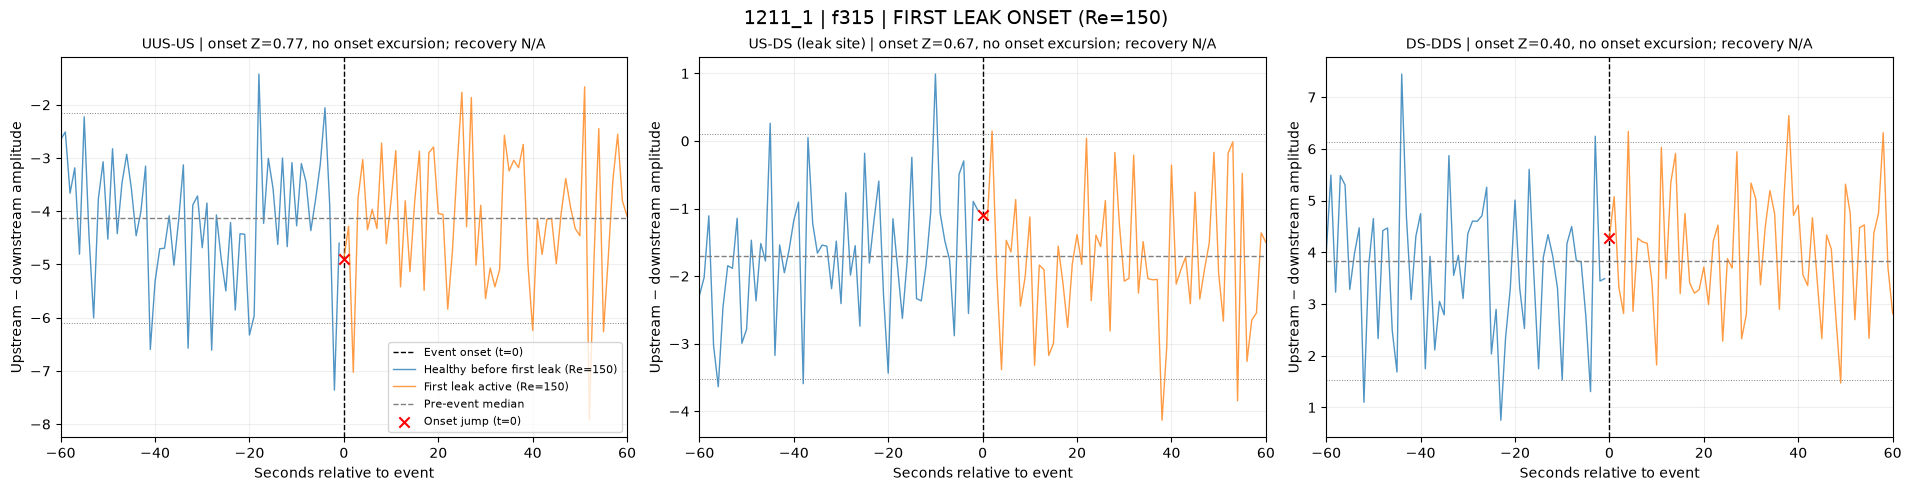

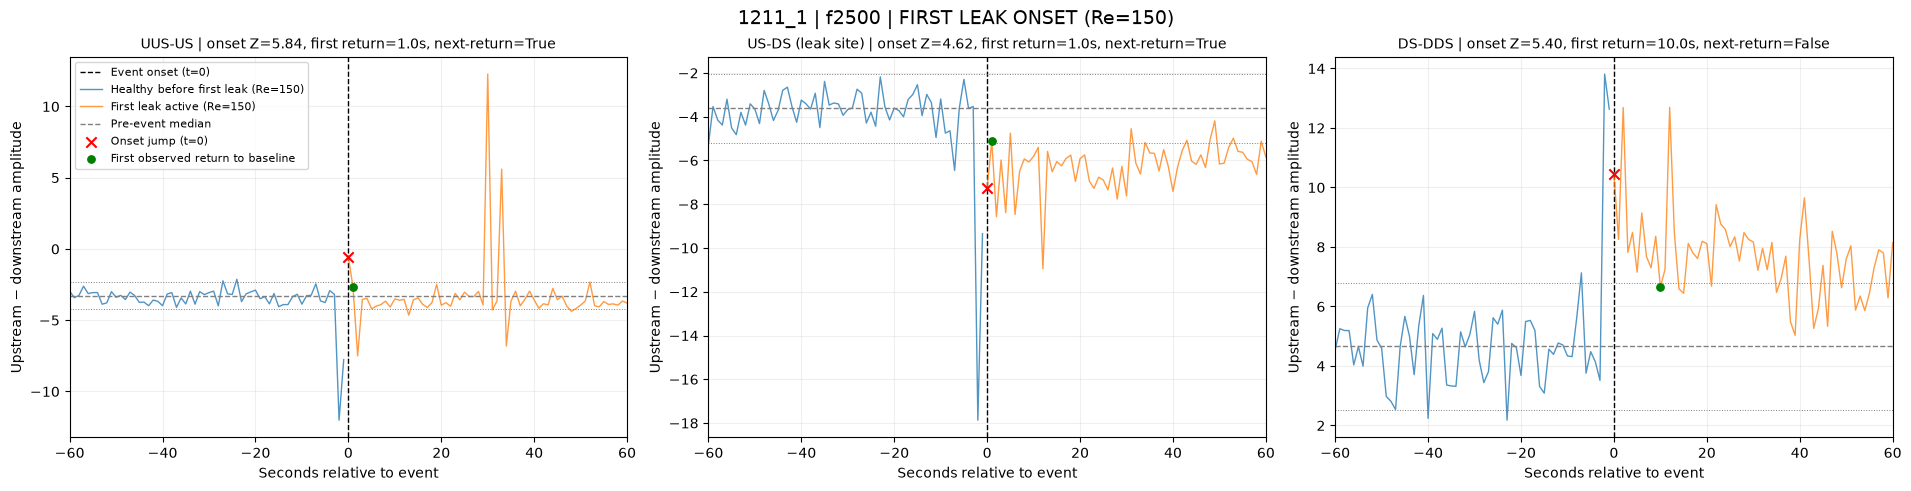

In [30]:
#event_types = [ 'first_leak',]
event_types = [ 'first_leak','re_100_to_150']

#freqs=PLOT_FREQUENCIES
freqs=["f315","f2500"]
#run_ids = sorted(df.run_id.unique())
run_ids=['1211_1',]
for frequency in freqs:
    for run in run_ids:
        for event_type in event_types[:1]:
            plot_files.append(str(plot_event_type(run, frequency, event_type)))


### Result interpretation — f315 versus f2500 in `1211_1`

- The two saved first-leak figures show **f315 onset Z ≈ 0.77 / 0.67 / 0.40** versus **f2500 onset Z ≈ 5.84 / 4.62 / 5.40**, ordered **UUS-US / US-DS / DS-DDS**.
- For f315, all three onset readings remain inside the baseline band and therefore show **no green recovery marker**. For f2500, the first observed returns are **1 s / 1 s / 10 s**.
- **Conclusion:** In this one experiment, f2500 separates the **instantaneous recorded onset** from ordinary pre-event fluctuations better than f315. The f2500 plots also show substantial pre-onset excursions and post-onset level differences; the first green-dot return **does not establish stable recovery**.


In [19]:
PLOT_FREQUENCIES[:2]
sorted(df.run_id.unique())[:1]

['1211_1']

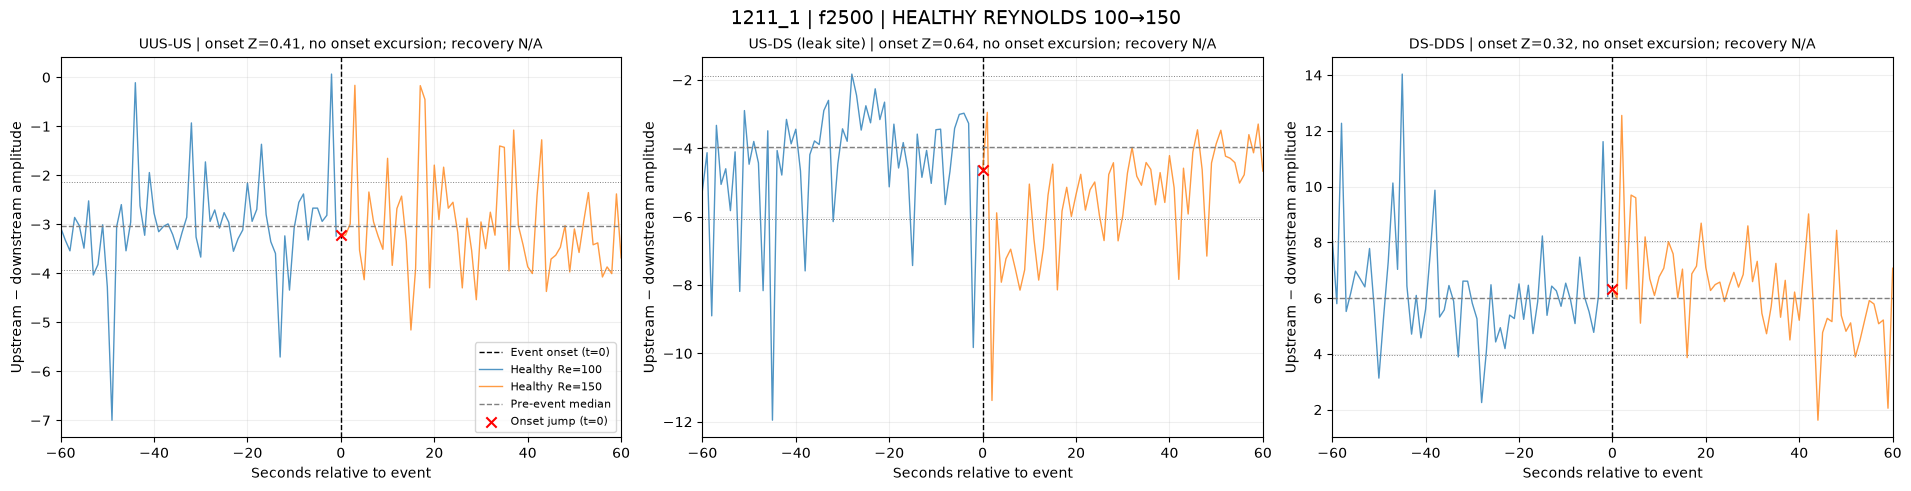

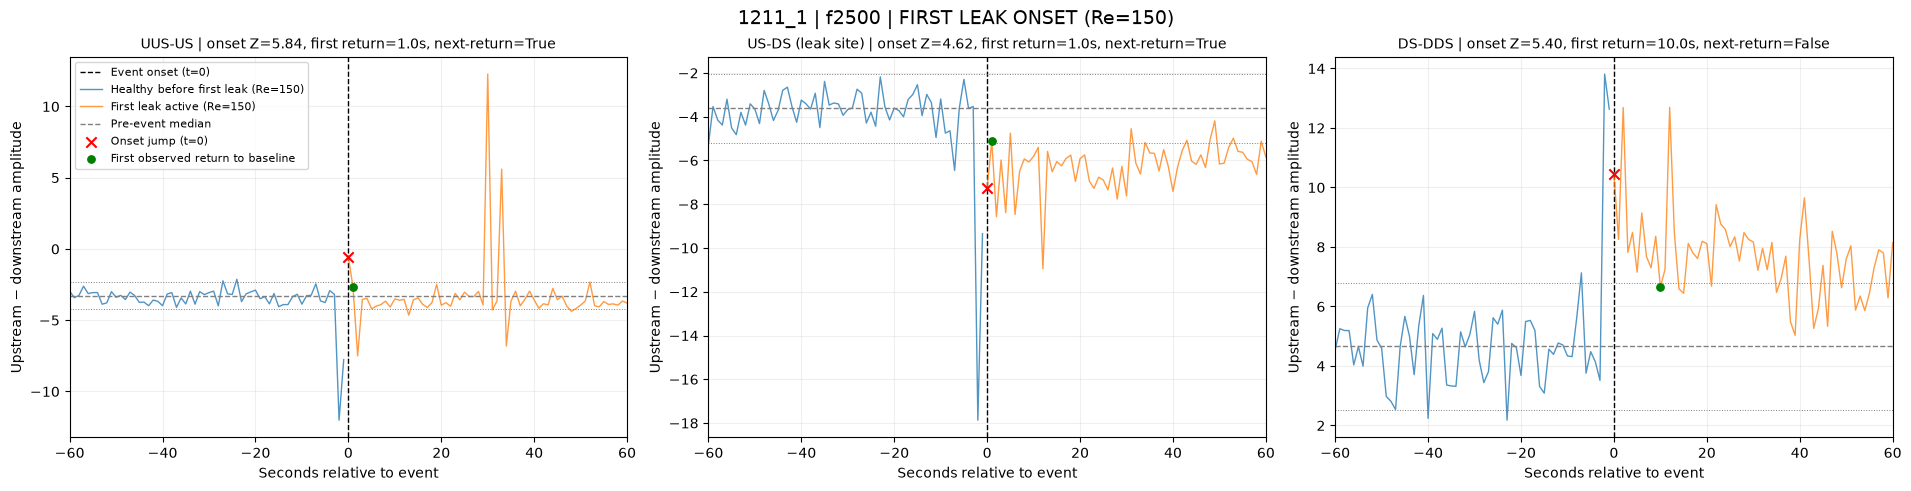

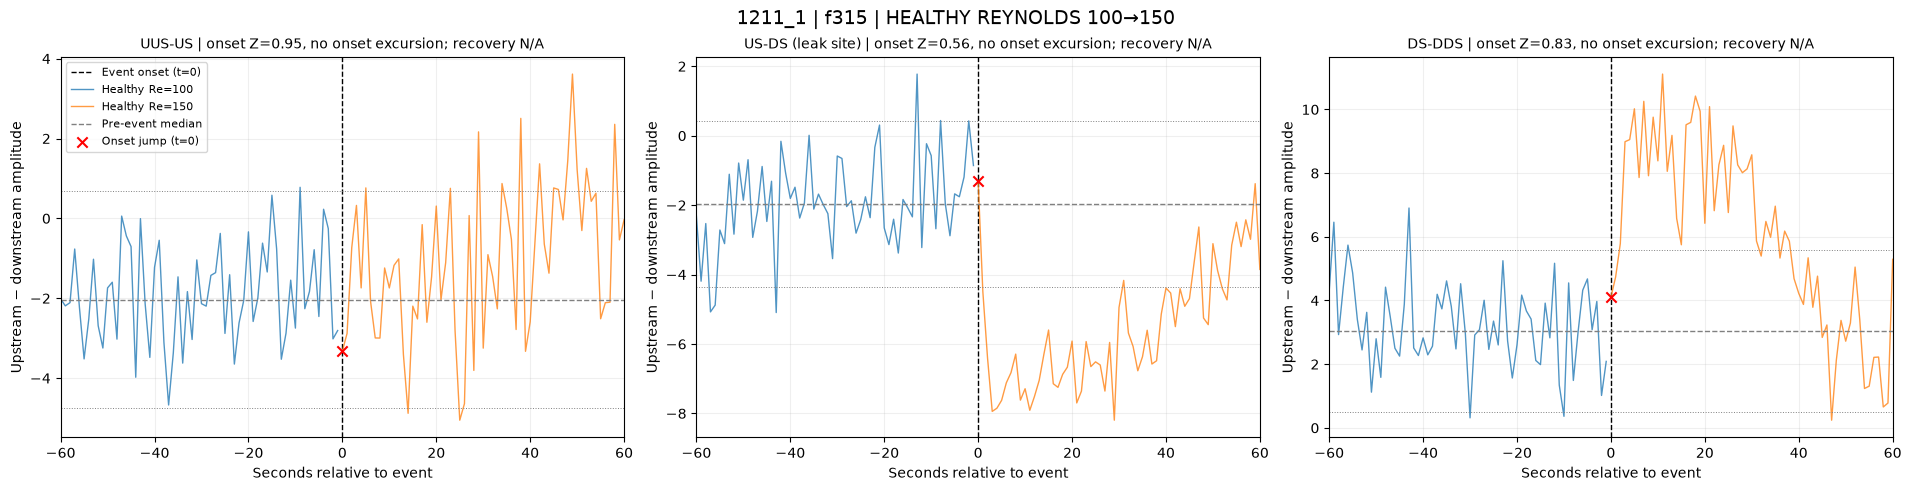

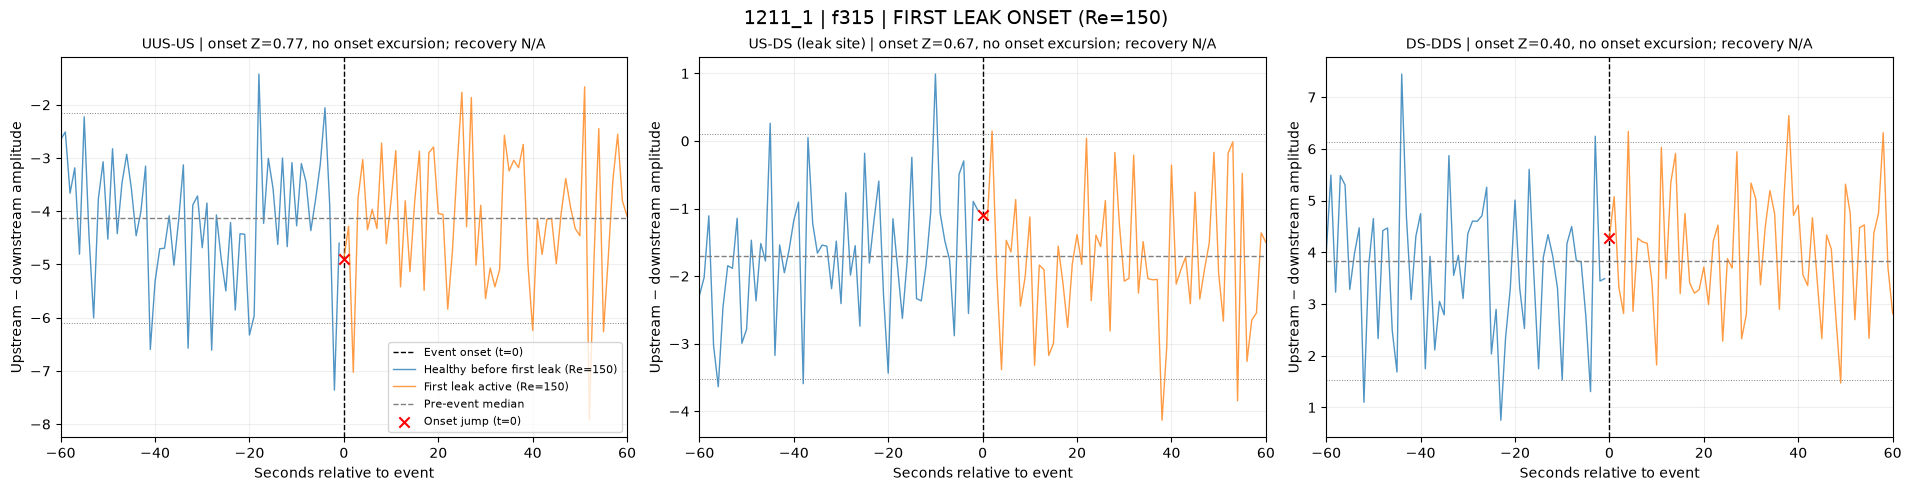

Plots generated: 4
Separate first-leak plots: 2
Separate Reynolds plots: 2


In [21]:
def plot_event_type(run, frequency, event_type):
    """Plot a single physical event separately: Reynolds transition OR first leak."""
    if frequency not in FREQUENCIES:
        raise ValueError(f'Frequency {frequency} not found; available: {FREQUENCIES}')
    if event_type not in ('re_100_to_150', 'first_leak'):
        raise ValueError(f'Unknown event_type: {event_type}')

    feature = f'upstream_minus_downstream__{frequency}'
    event_title = ('HEALTHY REYNOLDS 100→150' if event_type == 're_100_to_150'
                   else 'FIRST LEAK ONSET (Re=150)')
    pre_label = ('Healthy Re=100' if event_type == 're_100_to_150'
                 else 'Healthy before first leak (Re=150)')
    post_label = ('Healthy Re=150' if event_type == 're_100_to_150'
                  else 'First leak active (Re=150)')

    choices = events.loc[(events.run_id == run) &
                         events.event_type.eq(event_type)].sort_values('event_s')
    evt = choices.iloc[-1] if len(choices) else None

    fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), sharex=True,
                             layout='constrained', squeeze=False)
    for si, seg in enumerate(SEGMENTS):
        ax = axes[0, si]
        ax.axvline(0, ls='--', color='black', lw=1, label='Event onset (t=0)')
        if evt is None or (run, seg) not in segment_groups:
            ax.text(.5, .5, 'No event / segment', ha='center', va='center',
                    transform=ax.transAxes)
            ax.set_title(f'{seg} — no data')
            continue

        onset = float(evt.event_s)
        pre, post = event_windows(segment_groups[(run, seg)], run, onset, event_type)
        ax.plot(pre['Date-Time']-onset, pre[feature], alpha=.78, lw=1,
                color='tab:blue', label=pre_label)
        ax.plot(post['Date-Time']-onset, post[feature], alpha=.78, lw=1,
                color='tab:orange', label=post_label)
        rec = event_metrics.loc[(event_metrics.event_id == evt.event_id) &
                                event_metrics.segment_id.eq(seg) &
                                event_metrics.frequency.eq(frequency)]
        if len(rec):
            m = rec.iloc[0]
            if np.isfinite(m.baseline):
                ax.axhline(m.baseline, color='gray', lw=1, ls='--',
                           label='Pre-event median')
                if np.isfinite(m.baseline_sigma):
                    bound = RETURN_BAND_SIGMA*m.baseline_sigma
                    ax.axhline(m.baseline + bound, color='gray', lw=.7, ls=':')
                    ax.axhline(m.baseline - bound, color='gray', lw=.7, ls=':')
            if np.isfinite(m.peak_s):
                peak_y = post.loc[post['Date-Time'].eq(m.peak_s), feature]
                if len(peak_y):
                    ax.scatter([0.0], [peak_y.iloc[0]], marker='x', s=55,
                               color='red', zorder=4, label='Onset jump (t=0)')
            if np.isfinite(m.recovery_s):
                rec_y = post.loc[post['Date-Time'].eq(m.recovery_s), feature]
                if len(rec_y):
                    ax.scatter([m.recovery_s - onset], [rec_y.iloc[0]],
                               marker='o', s=28, color='green', zorder=4,
                               label='First observed return to baseline')
            if np.isfinite(m.peak_z) and m.peak_z <= RETURN_BAND_SIGMA:
                title_tail = (f' | onset Z={m.peak_z:.2f}, '
                              'no onset excursion; recovery N/A')
            elif np.isfinite(m.peak_z) and np.isfinite(m.recovery_time_s):
                title_tail = (f' | onset Z={m.peak_z:.2f}, '
                              f'first return={m.recovery_time_s:.1f}s, '
                              f'next-return={bool(m.next_sample_returned_to_baseline)}')
            elif np.isfinite(m.peak_z):
                title_tail = (f' | onset Z={m.peak_z:.2f}, '
                              f'no observed return; '
                              f'next-return={bool(m.next_sample_returned_to_baseline)}')
            else:
                title_tail = f' | status={m.status}'
        else:
            title_tail = ' | unavailable'

        ax.set_xlim(-PRE_WINDOW_S, POST_WINDOW_S)
        ax.set_title(seg + (' (leak site)' if seg == 'US-DS' else '') + title_tail,
                     fontsize=10)
        ax.set_xlabel('Seconds relative to event')
        ax.set_ylabel('Upstream − downstream amplitude')
        ax.grid(alpha=.2)
        if si == 0:
            ax.legend(loc='best', fontsize=8)

    fig.suptitle(f'{run} | {frequency} | {event_title}', fontsize=14)
    target = PLOTS / f'{run}__{frequency}__{event_type}__event_aligned.png'
    fig.savefig(target, dpi=130)
    plt.show()
    plt.close(fig)
    return target

plot_files = []
frequency_list =  PLOT_FREQUENCIES[:2]
experiment_list = sorted(df.run_id.unique())[:1]
for frequency in frequency_list:
    for run in experiment_list:
        for event_type in ('re_100_to_150', 'first_leak'):
            plot_files.append(str(plot_event_type(run, frequency, event_type)))
print('Plots generated:', len(plot_files))
print('Separate first-leak plots:', sum('__first_leak__' in p for p in plot_files))
print('Separate Reynolds plots:', sum('__re_100_to_150__' in p for p in plot_files))

### Result interpretation — 90 event-aligned context plots

- The saved output reports **90 figures**: **45 first-leak figures** and **45 healthy Reynolds-transition figures**, with three segment panels per figure. These figures **show context**; they do not change the t0-only scores.
- **Red X:** measured amplitude *at exactly t0*. **Green dot:** first observed post-t0 sample back within the original ±2 robust-noise band **after a qualifying t0 excursion**. Missing green dots can mean **no qualifying onset excursion** or **no observed return within 60 s**; check the panel title.
- Look for (a) excursions **before** the recorded t0, (b) differences that **persist after** a single in-band sample, and (c) differences between the three probe-pair responses. Such patterns can question event alignment or indicate sustained changes **not represented by `leak_peak_z` or first-return time**.
- **Conclusion:** The plots are a **diagnostic validity check** on the jump metric, not independent proof of leak detection or leak localization.


In [16]:
"""
for frequency in PLOT_FREQUENCIES:
    for run in sorted(df.run_id.unique()):
        for event_type in ['first_leak',]:
            plot_files.append(str(plot_event_type(run, frequency, event_type)))
"""

"\nfor frequency in PLOT_FREQUENCIES:\n    for run in sorted(df.run_id.unique()):\n        for event_type in ['first_leak',]:\n            plot_files.append(str(plot_event_type(run, frequency, event_type)))\n"

### Result interpretation — additional first-leak figures

- This cell **replots the 45 first-leak combinations** already included in the previous cell's 90 figures. These are **not 45 additional independent leak events**.
- **Conclusion:** Inspect these for the shape and persistence of changes during the first leak; the recorded Z ranking still uses **only t0**, and a green dot still indicates **one observed in-band sample**, not sustained stability.


## 8. Interpretation and validation

**The only eligible acoustic jump occurs at t0.** A peak at t0+5, t0+10, or t0+20 seconds is irrelevant to the event jump metric. Its size cannot affect the rankings or background comparisons. A recorded recovery requires `peak_z > RETURN_BAND_SIGMA` **and** `returned_to_baseline=True` (the onset must first leave the original baseline band), with `recovery_time_s` measuring elapsed seconds until the first observed return in the existing 60-second post window. The original `next_sample_returned_to_baseline` indicator distinguishes recovery at the very next sample. `peak_z` retains its prior column name for compatibility but now represents **t0 exclusively**.

Compare the same instantaneous jump to the healthy 100→150 event, and to event-free healthy pseudo-onsets. Large Reynolds-boundary jumps imply possible event confusion. These descriptive observations are **not** calibrated false-positive rates; real detector thresholds and independent temporal testing would be needed.


In [ ]:
# Enforce physical and temporal constraints without changing any source values.
assert all(event_metrics.loc[event_metrics.event_type=='re_100_to_150','event_s'] <
           event_metrics.loc[event_metrics.event_type=='re_100_to_150','run_id'].map(first_leak_by_run))
assert all(event_metrics.loc[event_metrics.event_type=='first_leak','event_s'] ==
           event_metrics.loc[event_metrics.event_type=='first_leak','run_id'].map(first_leak_by_run))
assert event_metrics[['event_id','segment_id','frequency']].duplicated().sum() == 0
assert comparison[['run_id','segment_id','frequency']].duplicated().sum() == 0
assert len(FREQUENCIES) == len(set(FREQUENCIES))
assert (comparison.loc[comparison.leak_peak_z.notna(), 'leak_peak_z'] >= 0).all()
assert ((comparison.healthy_peak_exceedance_fraction.dropna() >= 0) &
        (comparison.healthy_peak_exceedance_fraction.dropna() <= 1)).all()
if not sham_metrics.empty:
    assert sham_metrics['event_s'].lt(sham_metrics['run_id'].map(first_leak_by_run)).all()
print('Verified: first-leak boundaries, pre-first-leak Reynolds events,')
print('          unique run/segment/frequency measurements, bounded sham exceedance.')
print('Summary outputs:')
for p in sorted(OUT.glob('*.csv')):
    print('  ',p.name)
print('Generated plots:',len(plot_files))
# Every successfully detected jump MUST be at the event timestamp, not later.
valid = event_metrics.loc[event_metrics.peak_s.notna()]
assert np.allclose(valid['peak_s'], valid['event_s'])
assert valid['time_to_peak_s'].eq(0).all()
assert (valid.loc[valid.returned_to_baseline, 'recovery_time_s'] > 0).all()
assert event_metrics.loc[event_metrics.next_sample_returned_to_baseline, 'returned_to_baseline'].all()
assert np.allclose(
    event_metrics.loc[event_metrics.next_sample_returned_to_baseline, 'recovery_time_s'],
    event_metrics.loc[event_metrics.next_sample_returned_to_baseline, 'next_sample_s'] -
    event_metrics.loc[event_metrics.next_sample_returned_to_baseline, 'event_s']
)
assert event_metrics.loc[event_metrics.returned_to_baseline, 'recovery_time_s'].le(POST_WINDOW_S).all()
# A green recovery marker must only be possible after a genuine t0 excursion.
no_excursion = event_metrics.peak_z.notna() & event_metrics.peak_z.le(RETURN_BAND_SIGMA)
assert not event_metrics.loc[no_excursion, 'returned_to_baseline'].any()
assert not event_metrics.loc[no_excursion, 'next_sample_returned_to_baseline'].any()
assert event_metrics.loc[no_excursion, 'recovery_time_s'].isna().all()
assert event_metrics.loc[no_excursion, 'recovery_s'].isna().all()
assert event_metrics.loc[event_metrics.returned_to_baseline, 'peak_z'].gt(RETURN_BAND_SIGMA).all()
print('Verified: jumps only at t0; recovery requires onset outside original band.')


### Final conclusions and validation status

**Findings from saved outputs:** Some frequencies—especially **f2500 and f3100**—show pronounced immediate leak-onset excursions compared with their corresponding Reynolds transitions and sampled healthy pseudo-onsets in **four runs**. The `1213_1` run is a clear limitation. Large responses in segments **away from the physical leak** mean jump magnitude alone does not localize the leak. Recovery times are **first band re-entries**, not sustained recovery.

**What has not been established:** A detector working without known onset timestamps, calibrated false alarms per hour, sensitivity on independent runs, or sustained leak-state identification. Large Z values do not prove these capabilities.

**Validation status:** The code cell immediately above contains assertions for event timing, unique comparisons, t0-only jumps, and valid recovery markers, **but it has no saved execution output in the uploaded notebook**. Its execution is therefore **not verified from this file**. The notebook's original code and saved results are otherwise preserved.
